# Boston 311 Crew Planner: demo notebook

DADS5250 Generative AI in Practice, Module 7 Hackathon, Group 09: John Baldwin, Nicholas Maar, Adam Jaroudi, Andrew Lai.

> **[AI-authored: Claude]** This notebook and the `boston311` package it calls were written by Claude (Anthropic) from the team's architecture spec (`docs/architecture.md`). See `docs/authorship.md` for who wrote what and how AI was used.

**What this notebook does.** It runs the whole product end to end:

1. **Data.** Real 2023 and 2024 Boston 311 requests, fetched from data.boston.gov's API and reduced to small committed tables.
2. **Forecast.** Monthly 2025 demand per department (seasonal naive).
3. **Staffing plan.** A month-by-month hire / release / seasonal-crew plan, made on a *planning* workload, frozen, then scored on a separate *evaluation* workload with a daily queue simulator.
4. **Sensitivity.** The frozen plan and the fixed-crew baseline replayed on +20%, -20%, and snowstorm workloads.
5. **Intake assistant.** A LangGraph agent with retrieval (RAG) and structured output that routes plain-language messages to an official request type and department, with accuracy on a 40-message test set.
6. **Other consideration.** Neighborhood equity in historical response times.

**Modes.** `MODE = "offline"` (the default) replays recorded model answers, so the notebook runs with **no API key and no network**. `MODE = "live"` calls OpenAI (`gpt-6.1-sol`) for anything not yet recorded and needs `OPENAI_API_KEY` in `.env`. Offline results are the recorded live answers, not new model calls.

This is a demonstration. It never submits a request to the city and never promises a completion date.

In [1]:
MODE = "offline"   # "offline" (no key needed) or "live" (needs OPENAI_API_KEY in .env)

import pandas as pd
import matplotlib.pyplot as plt
from boston311 import config, data, forecast, workload, staffing, evaluate, equity, manifest
from boston311.agent import IntakeAssistant

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("mode:", MODE, "| model:", config.LLM_MODEL, "| prompt:", config.PROMPT_VERSION, "| catalog:", config.CATALOG_VERSION)

mode: offline | model: gpt-6.1-sol | prompt: classify-v2 | catalog: catalog-v2


## 1. Data and reconciliation

The raw files (about 180 MB each) are downloaded once by `python scripts/build_data.py` through the CKAN API of data.boston.gov and checked against the checksum the city publishes. They are not needed to run this notebook: the small count tables in `data/processed/` are committed.

Our 2024 counts for the four departments must match the project page exactly.

In [2]:
recon = data.load_reconciliation()
display(pd.DataFrame(recon["page_check_2024"]).T)
display(pd.DataFrame(recon["by_year"]).T[["rows_read", "duplicates_removed", "out_of_scope_departments_excluded", "in_scope_rows", "target_classes"]])
display(pd.DataFrame(recon["sources"])[["year", "size_bytes", "md5", "last_modified"]])

,page,ours,match
PWDx,157610,157610,True
BTDT,81447,81447,True
PARK,18736,18736,True
ISD,18624,18624,True


,rows_read,duplicates_removed,out_of_scope_departments_excluded,in_scope_rows,target_classes
2023,307791,0,25545,282246,"{'valid': 231524, 'missing': 50722, 'invalid_o..."
2024,306756,0,30339,276417,"{'valid': 244996, 'missing': 31421, 'invalid_o..."


,year,size_bytes,md5,last_modified
0,2023,184129946,beb0947323226eb7d9a6abd2207e4635,2026-09-18T01:27:26.805931
1,2024,182147317,99da78a9b838728d35d52658b7011a15,2026-09-18T01:27:27.630670


## 2. 2025 demand forecast

**Seasonal naive**: each 2025 month equals the same month of 2024. With only two years of history, a fancier model cannot be validated fairly, so the spec keeps the baseline. The backtest shows how the same method would have done one year earlier (predicting 2024 from 2023).

In [3]:
fc = forecast.forecast_2025()
display(fc.pivot(index="month", columns="department", values="forecast")[list(config.DEPT_CODES)])
display(forecast.backtest())

department,PWDx,BTDT,PARK,ISD
month,,,,
1,13582,5620,928,1491
2,11550,5954,794,1285
3,13092,7209,1291,1342
4,13998,7008,1519,1415
5,13333,7511,2029,1555
6,12917,7176,2881,1779
7,13915,6678,2640,1796
8,16398,6719,2143,2077
9,15912,7633,1587,1809


,department,forecast_total,actual_total,mape_pct,annual_bias_pct
0,PWDx,171268,157610,13.60,8.70
1,BTDT,75314,81447,7.60,-7.50
2,PARK,17541,18736,17.70,-6.40
3,ISD,18123,18624,13.30,-2.70


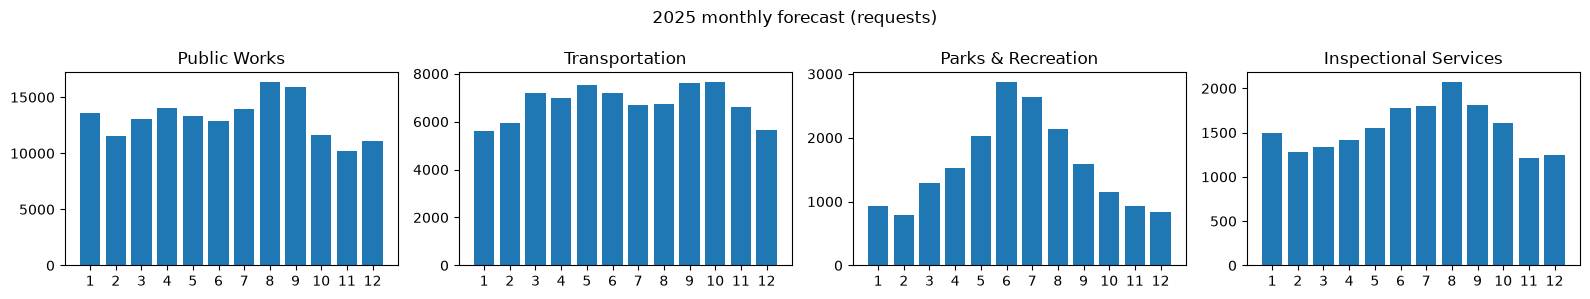

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, dept in zip(axes, config.DEPT_CODES):
    d = fc[fc.department == dept]
    ax.bar(d.month, d.forecast)
    ax.set_title(config.DEPARTMENTS[dept].name)
    ax.set_xticks(range(1, 13))
fig.suptitle("2025 monthly forecast (requests)")
plt.tight_layout(); plt.show()

## 3. Workloads

The simulator needs individual requests with deadlines, not just monthly totals. A **workload** is the full list of 2025 requests: arrival day, type, and target date.

* Arrival counts are deterministic: exact rounding of the forecast and the 2024 type mix.
* Target dates are drawn from 2023 to 2024 history with a seeded random generator.
* There are two independent streams. The **planning** workload is the only one the planner sees. The **base evaluation** workload scores the frozen plan.
* The +20%, -20%, and snowstorm workloads are built *from* the base evaluation workload, only adding or removing requests.

In [5]:
wl = workload.build_all_workloads(fc)
display(pd.DataFrame({name: {"requests": len(w.requests),
                             "with target date": int((w.requests.target_class == "valid").sum()),
                             "no target date": int((w.requests.target_class != "valid").sum())}
                      for name, w in wl.items()}).T)

,requests,with target date,no target date
planning,276417,244997,31420
base,276417,245000,31417
plus20,331701,294010,37691
minus20,221133,195884,25249
spike,278905,246832,32073


## 4. The frozen staffing plan

At the start of each month, using projections on the planning workload only:

* **Parks seasonal crews** (April to October): the fewest crews that avoid every avoidable overdue request.
* **Hire** only if a shortage is projected in *both* of the next two months, and hire the smaller shortage. Hiring stops after October. Parks never starts a permanent crew in season.
* **Release** only if no hire was ordered and a five-month projection shows no more penalty events, no higher cost (severance counted), and no bigger backlog. Releases stop after August.

After December the decisions are frozen.

In [6]:
plan = staffing.make_plan(wl["planning"])
baseline = staffing.baseline_plan()
pf = plan.to_frame()
display(pf.pivot(index="month", columns="department", values=["regular_crews", "hires_ordered", "releases_noticed", "seasonal_crews"]))
for dept, dp in plan.departments.items():
    for line in dp.log:
        print(f"{dept}: {line}")

regular_crews               hires_ordered               releases_noticed               seasonal_crews              
department          BTDT ISD PARK PWDx          BTDT ISD PARK PWDx             BTDT ISD PARK PWDx           BTDT ISD PARK PWDx
month                                                                                                                         
1                     18  16   10   50             3   2    0    2                0   0    0    0              0   0    0    0
2                     21  18   10   52             2   0    0    0                0   0    0    0              0   0    0    0
3                     23  18   10   52             1   0    0    6                0   0    0    0              0   0    0    0
4                     24  18   10   58             1   1    0    0                0   0    0    0              0   0    5    0
5                     25  19   10   58             0   4    0    0                0   0    0    0              0   0   10    0
6                     25  23   10   58             0   0    0    0                0   0    0    0              0   0   21    0
7                     25  23   10   58             0   2    0   12                0   0    0    0              0   0   13    0
8                     25  25   10   70             1   0    0    0                0   0    0    0              0   0   32    0
9                     26  25   10   70             0   0    0    0                0   0    0    0              0   0   11    0
10                    26  25   10   70             0   0    0    0                0   0    0    0              0   0    3    0
11                    26  25   10   70             0   0    0    0                0   0    0    0              0   0    0    0
12                    26  25   10   70             0   0    0    0                0   0    0    0              0   0    0    0

PWDx: month 1: projected shortage 2 crews in month 2 and 4 in month 3; ordered 2 hire(s), productive from month 2
PWDx: month 3: projected shortage 6 crews in month 4 and 7 in month 5; ordered 6 hire(s), productive from month 4
PWDx: month 7: projected shortage 12 crews in month 8 and 17 in month 9; ordered 12 hire(s), productive from month 8
BTDT: month 1: projected shortage 3 crews in month 2 and 8 in month 3; ordered 3 hire(s), productive from month 2
BTDT: month 2: projected shortage 2 crews in month 3 and 4 in month 4; ordered 2 hire(s), productive from month 3
BTDT: month 3: projected shortage 1 crews in month 4 and 3 in month 5; ordered 1 hire(s), productive from month 4
BTDT: month 4: projected shortage 2 crews in month 5 and 1 in month 6; ordered 1 hire(s), productive from month 5
BTDT: month 8: projected shortage 1 crews in month 9 and 2 in month 10; ordered 1 hire(s), productive from month 9
PARK: month 4: 5 seasonal crew(s)
PARK: month 5: 10 seasonal crew(s)
PARK: month 6: 

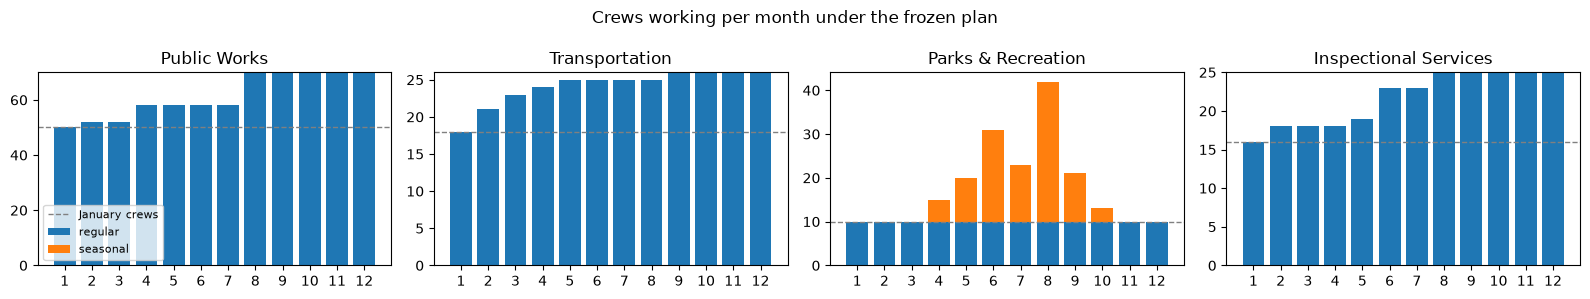

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, dept in zip(axes, config.DEPT_CODES):
    d = pf[pf.department == dept]
    ax.bar(d.month, d.regular_crews, label="regular")
    ax.bar(d.month, d.seasonal_crews, bottom=d.regular_crews, label="seasonal")
    ax.axhline(config.DEPARTMENTS[dept].start_crews, color="grey", ls="--", lw=1, label="January crews")
    ax.set_title(config.DEPARTMENTS[dept].name); ax.set_xticks(range(1, 13))
axes[0].legend(fontsize=8)
fig.suptitle("Crews working per month under the frozen plan")
plt.tight_layout(); plt.show()

## 5. Scoring: frozen plan vs. fixed January crews

Both plans are scored by the same daily simulator on the same **base evaluation** workload, which the planner never saw. Each scenario produces 48 staffing rows (4 departments x 12 months). Full reconciliation checks run on every plan and scenario: request flow, workforce, penalties, and costs.

In [8]:
scored, summaries = {}, []
for p in (plan, baseline):
    for scenario in config.SCENARIOS:
        rows, year_ends = staffing.score_plan(p, wl[scenario], scenario)
        assert staffing.reconciliation_failures(rows, p, wl[scenario]) == [], (p.name, scenario)
        scored[(p.name, scenario)] = (rows, year_ends)
        summaries.append(staffing.summarize(rows, year_ends))
summary = pd.concat(summaries, ignore_index=True)
print("Reconciliation checks passed for all", len(scored), "plan x scenario combinations.")
base_cmp = summary[summary.scenario == "base"].set_index(["department", "plan"])[["staff_cost", "penalty_cost", "total_cost", "overdue_events", "long_overdue_events", "on_time_rate", "open_dec31"]]
display(base_cmp.unstack("plan"))

Reconciliation checks passed for all 8 plan x scenario combinations.


staff_cost               penalty_cost               total_cost               overdue_events           long_overdue_events           on_time_rate           open_dec31          
plan            baseline     heuristic     baseline  heuristic      baseline     heuristic       baseline heuristic            baseline heuristic     baseline heuristic   baseline heuristic
department                                                                                                                                                                                   
ALL        11,920,000.00 16,495,000.00 7,554,180.00 474,820.00 19,474,180.00 16,969,820.00         176829     23741               40176         0         0.22      0.90      27579      1444
BTDT        1,980,000.00  2,731,666.67 4,814,240.00 177,680.00  6,794,240.00  2,909,346.67          69367      8884               34269         0         0.12      0.89      13865       483
ISD         2,240,000.00  3,138,333.33   288,560.00  18,580.00  2,528,560.00  3,156,913.33           6328       929                1620         0         0.57      0.94       2496        50
PARK        1,200,000.00  2,435,000.00   546,340.00   3,240.00  1,746,340.00  2,438,240.00           5882       162                4287         0         0.21      0.98       4434        45
PWDx        6,500,000.00  8,190,000.00 1,905,040.00 275,320.00  8,405,040.00  8,465,320.00          95252     13766                   0         0         0.25      0.89       6784       866

### Dynamic staffing table (base scenario, frozen plan)

One row per department and month. Events (hires, closures, penalties) are kept separate from month-end inventory (open requests by status).

In [9]:
rows, _ = scored[("heuristic", "base")]
display(rows[["department", "month", "regular_crews", "hires_ordered", "releases_noticed", "seasonal_crews", "capacity",
              "arrivals", "closed", "overdue_events", "long_overdue_events", "open_end", "total_cost"]])

,department,month,regular_crews,hires_ordered,releases_noticed,seasonal_crews,capacity,arrivals,closed,overdue_events,long_overdue_events,open_end,total_cost
0,PWDx,1,50,2,0,0,12600,13582,12226,1683,0,1356,"596,993.33"
1,PWDx,2,52,0,0,0,13104,11550,12906,2366,0,0,"610,653.33"
2,PWDx,3,52,6,0,0,13104,13092,12506,818,0,586,"644,693.33"
3,PWDx,4,58,0,0,0,14616,13998,13735,810,0,849,"644,533.33"
4,PWDx,5,58,0,0,0,14616,13333,13363,1099,0,819,"650,313.33"
5,PWDx,6,58,0,0,0,14616,12917,13199,1055,0,537,"649,433.33"
6,PWDx,7,58,12,0,0,14616,13915,13260,910,0,1192,"776,533.33"
7,PWDx,8,70,0,0,0,17640,16398,16574,2548,0,1016,"809,293.33"
8,PWDx,9,70,0,0,0,17640,15912,15726,1033,0,1202,"778,993.33"
9,PWDx,10,70,0,0,0,17640,11639,12130,582,0,711,"769,973.33"


## 6. Sensitivity analysis

The *frozen* plan (no re-planning) and the baseline replayed on demand 20% higher, 20% lower, and a snowstorm: Public Works arrivals tripled on February 10 to 12, 2025.

staff_cost                penalty_cost                 total_cost               on_time_rate           open_dec31          
plan          baseline     heuristic      baseline    heuristic      baseline     heuristic     baseline heuristic   baseline heuristic
scenario                                                                                                                               
base     11,920,000.00 16,495,000.00  7,554,180.00   474,820.00 19,474,180.00 16,969,820.00         0.22      0.90      27579      1444
plus20   11,920,000.00 16,495,000.00 21,284,560.00 4,672,980.00 33,204,560.00 21,167,980.00         0.08      0.15      81746     10690
minus20  11,920,000.00 16,495,000.00  1,171,560.00   199,920.00 13,091,560.00 16,694,920.00         0.75      0.95       2570       925
spike    11,920,000.00 16,495,000.00  8,438,820.00   837,020.00 20,358,820.00 17,332,020.00         0.16      0.82      30067      1444

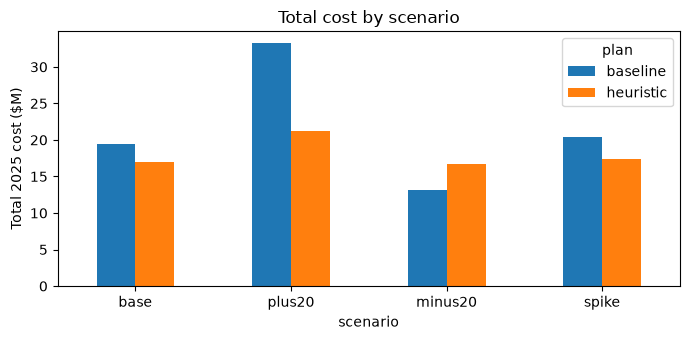

In [10]:
tot = summary[summary.department == "ALL"].set_index(["scenario", "plan"])[["staff_cost", "penalty_cost", "total_cost", "on_time_rate", "open_dec31"]]
display(tot.unstack("plan").reindex(list(config.SCENARIOS)))
ax = (summary[summary.department == "ALL"].pivot(index="scenario", columns="plan", values="total_cost").reindex(list(config.SCENARIOS)) / 1e6).plot.bar(rot=0, figsize=(7, 3.5))
ax.set_ylabel("Total 2025 cost ($M)"); ax.set_title("Total cost by scenario"); plt.tight_layout(); plt.show()

### Year-end disclosures (base scenario, frozen plan)

Costs count only within 2025. Requests still open on December 31 are classified, not silently dropped.

In [11]:
_, ye = scored[("heuristic", "base")]
display(pd.DataFrame([y.__dict__ for y in ye]))

,department,costs_accrued,open_overdue_charged,open_long_overdue_charged,long_threshold_in_2026,not_yet_due,open_no_target,hires_ordered_effective_2026,notices_effective_2026,due_in_2025,on_time_rate
0,PWDx,"8,465,320.00",176,0,176,622,68,0,0,126732,0.89
1,BTDT,"2,909,346.67",160,0,160,320,3,0,0,78890,0.89
2,PARK,"2,438,240.00",1,0,1,44,0,0,0,7474,0.98
3,ISD,"3,156,913.33",0,0,0,50,0,0,0,14808,0.94


## 7. The intake assistant

Flow: **retrieve** candidate official types (TF-IDF over names, descriptions, and reviewed aliases) -> **classify** once with structured output -> **validate in code** -> **route**, **clarify** (one LangGraph interrupt), or **triage**. The model only proposes a type; code assigns the department and queue from reviewed mappings.

Two-tier routing: a type routes to its **department** when one in-scope department handled at least 90% of its handled requests. It names an **exact queue** only when one queue handled at least 90%; otherwise the reply says the queue is assigned by location or by the department.

In [12]:
assistant = IntakeAssistant(mode=MODE)
demo = ["A car is parked in front of my driveway and I can't get out.",
        "dead raccoon in the middle of the road on Adams St",
        "Huge pothole on Tremont St near the Park Street T stop. It almost blew out my tire.",
        "Someone broke into my car last night and stole my laptop.",
        ""]
for msg in demo:
    r = assistant.run(msg)
    print(f"MESSAGE: {msg!r}\nDECISION: {r.decision.value}\n{r.response_text}\n" + "-" * 80)

MESSAGE: "A car is parked in front of my driveway and I can't get out."
DECISION: ROUTE
This looks like a "Parking Enforcement" request, handled by Transportation. It would go to the BTDT_Parking Enforcement queue. Historically (2023-2024), 57% of these requests with a target date were closed on time, and the median time to close was 0.7 days. This is past performance, not a promise.

This is a demonstration assistant: nothing has been submitted to the City of Boston, and no completion date is promised.
--------------------------------------------------------------------------------
MESSAGE: 'dead raccoon in the middle of the road on Adams St'
DECISION: ROUTE
This looks like a "Pick up Dead Animal" request, handled by Public Works. The exact queue is assigned by location (the district or region of the address). Historically (2023-2024), 98% of these requests with a target date were closed on time, and the median time to close was 0.1 days. This is past performance, not a promise.

This

In [13]:
# A clarification round trip: the assistant asks one question, then routes.
turn = assistant.submit("There's a light out.")
print("ASSISTANT ASKS:", turn.question)
turn = assistant.answer(turn.thread_id, "It's a street light on the sidewalk in front of my house on Dorchester Ave.")
print("DECISION:", turn.result.decision.value)
print(turn.result.response_text)

ASSISTANT ASKS: Is it a streetlight, a traffic signal, or a light in a park?
DECISION: ROUTE
This looks like a "Street Light Outages" request, handled by Public Works. The department assigns the exact queue. Historically (2023-2024), 56% of these requests with a target date were closed on time, and the median time to close was 4.5 days. This is past performance, not a promise.

This is a demonstration assistant: nothing has been submitted to the City of Boston, and no completion date is promised.


### Accuracy on the dev and test sets (demonstration evaluation)

* **Test set:** 40 messages covering clear requests, paraphrases, confusions, missing context, multiple issues, out-of-scope requests, and empty input. It was never used for tuning.
* **Dev set:** 18 separate messages, used to tune the prompt and the retrieval gate.
* Both sets were written by Claude and are pending team review.

In [14]:
results = {name: evaluate.run_set(assistant, evaluate.load_set(name)) for name in ("dev", "test")}
display(pd.concat({name: evaluate.metrics_table(df).set_index("metric") for name, df in results.items()}, axis=1))
display(evaluate.retrieval_recall(evaluate.load_set("dev")))

dev                  test              
                                            correct total percent correct total percent
metric                                                                                 
decision accuracy                                18    18  100.00      40    40  100.00
type accuracy                                    15    15  100.00      33    34   97.10
department accuracy                              12    13   92.30      30    31   96.80
queue accuracy (exact queues)                     8     8  100.00      19    20   95.00
queue accuracy (location/department labels)       4     5   80.00      10    11   90.90
auto-route precision                             12    12  100.00      29    30   96.70
auto-route coverage                              12    13   92.30      30    31   96.80
clarification rate                                3    18   16.70       8    40   20.00
triage rate                                       5    18   27.80       8    40   20.00

,aliases,k,found,items,recall_pct
0,True,8,15,15,100.00
1,False,8,7,15,46.70


In [15]:
t = results["test"]
wrong = t[(t.decision_ok == False) | (t.type_ok == False) | (t.department_ok == False) | (t.queue_ok == False)]
display(wrong[["id", "category", "message", "expected_type_id", "type_id", "type_name", "decision", "triage_reason"]])

,id,category,message,expected_type_id,type_id,type_name,decision,triage_reason
19,t20,paraphrase,the restaurant on the corner has mice running ...,T149,T115,Rodent Activity,ROUTE,NaN
24,t25,confusion,The public trash can at the bus stop on Washin...,T050,T025,Empty Litter Basket,TRIAGE,"""Empty Litter Basket"" is not handled consisten..."


## 8. Other consideration: neighborhood equity (2023 to 2024, historical)

Did some neighborhoods get less on-time service *for the same kinds of requests*? The **expected** rate is what a neighborhood would get if each of its requests were served at that type's citywide on-time rate. **Gap** = actual minus expected, in percentage points.

This analysis is descriptive, not causal, and has no population data.

,department,neighborhoods,raw_on_time_min,raw_on_time_max,largest_negative_gap,largest_positive_gap
0,PWDx,17,0.75,0.91,Downtown / Financial District (-2.2 pts),East Boston (+4.4 pts)
1,BTDT,17,0.44,0.68,West Roxbury (-13.3 pts),South Boston / South Boston Waterfront (+10.8 ...
2,PARK,17,0.87,0.95,Dorchester (-1.3 pts),Beacon Hill (+3.8 pts)
3,ISD,17,0.65,0.79,Charlestown (-4.1 pts),South Boston / South Boston Waterfront (+2.7 pts)


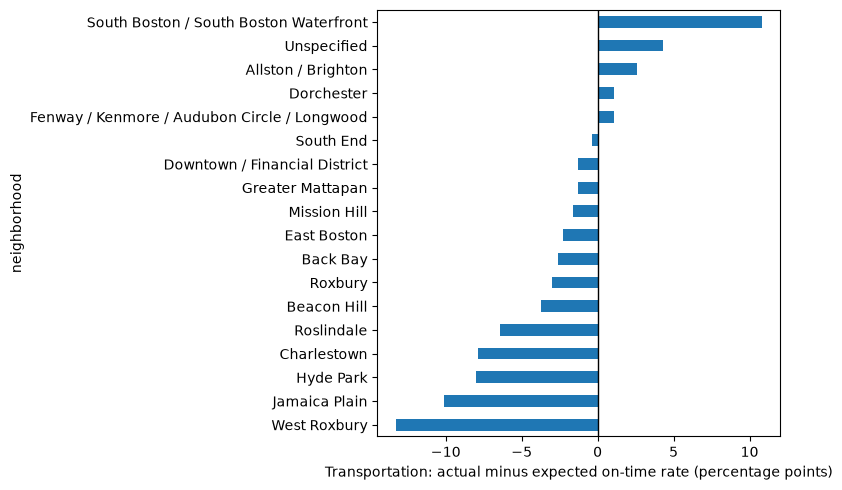

In [16]:
eq = equity.neighborhood_equity()
display(equity.equity_summary(eq))
btdt = eq[(eq.department == "BTDT") & ~eq.small_sample].sort_values("gap_pct_points")
ax = btdt.plot.barh(x="neighborhood", y="gap_pct_points", legend=False, figsize=(8, 5))
ax.axvline(0, color="black", lw=1); ax.set_xlabel("Transportation: actual minus expected on-time rate (percentage points)")
plt.tight_layout(); plt.show()

## 9. Run manifest

Everything needed to check this run: input checksums, parameters, seeds, model and prompt versions, mode, and package versions.

In [17]:
m = manifest.build_manifest(MODE, outputs=[])
print({k: m[k] for k in ("created_utc", "mode", "training_cutoff", "seeds", "model")})
print(len(m["inputs"]), "input files checksummed; git commit:", m["environment"]["git_commit"])

{'created_utc': '2026-10-23T04:38:57+00:00', 'mode': 'offline', 'training_cutoff': '2024-12-31', 'seeds': {'planning': 20250101, 'evaluation': 20251231}, 'model': {'provider': 'openai', 'id': 'gpt-6.1-sol', 'reasoning_effort': 'low', 'seed': 5250, 'prompt_version': 'classify-v2', 'alias_prompt_version': 'aliases-v2', 'catalog_version': 'catalog-v2'}}
19 input files checksummed; git commit: 58c311a4377f7d8e5ce3242476524ff82f59edba-dirty


## Notes and limits

* **Challenge model.** Capacity, cost, starting crews, and penalties are the project page's assumptions, not Boston's real operations. The 21-service-day calendar is synthetic.
* **Evaluation workloads are synthetic.** The plan is scored on a separately seeded synthetic workload, not on real unseen 2025 requests.
* **Pending team review.** Mappings and aliases are provisionally approved by Claude. The test and dev messages are AI-written.
* **Open design question.** The spec's Parks seasonal rule is not cost-aware: Parks costs more under the plan than under the baseline. See `docs/report.md`.
* **AI use.** See `docs/authorship.md`.